# 02 — Sales modelling

Saved outputs are historical results from the supplied notebooks. Edited cells have cleared outputs. Run in order from a fresh kernel to reproduce; **Run All in notebooks 02 and 03 retrains models**. Keep your existing models and predictions.


In [2]:
%pip install scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", None)

print("Python version:", sys.version.split()[0])
print("Scikit-learn version:", sklearn.__version__)
print("Current folder:", Path.cwd())
print("Modelling imports successful!")

Python version: 3.13.7
Scikit-learn version: 1.9.0
Current folder: d:\DigiCrome Academy\Internship\Nexthikes\P6\Notebooks\02_sales_modelling.ipynb
Modelling imports successful!


In [4]:
# Locate the project's data folder.
current_folder = Path.cwd()

data_dir = next(
    (
        folder / "data"
        for folder in [current_folder, *current_folder.parents]
        if (folder / "data" / "train.csv").is_file()
    ),
    None,
)

if data_dir is None:
    raise FileNotFoundError("Could not locate data/train.csv")

project_dir = data_dir.parent

# Load original data independently of the EDA notebook.
train = pd.read_csv(
    data_dir / "train.csv",
    parse_dates=["Date"],
    dtype={"StateHoliday": "string"},
)

test = pd.read_csv(
    data_dir / "test.csv",
    parse_dates=["Date"],
    dtype={"StateHoliday": "string"},
)

store = pd.read_csv(data_dir / "store.csv")

def merge_store_data(daily_data, store_data):
    merged = daily_data.merge(
        store_data,
        on="Store",
        how="left",
        validate="many_to_one",
        indicator=True,
    )

    assert len(merged) == len(daily_data), "Row count changed."
    assert merged["_merge"].eq("both").all(), "Unmatched store IDs."

    return merged.drop(columns="_merge")

train_merged = merge_store_data(train, store)
test_merged = merge_store_data(test, store)

# Reserve the final 42 calendar days.
validation_end = train_merged["Date"].max()
validation_start = validation_end - pd.Timedelta(days=41)

train_part = train_merged.loc[
    train_merged["Date"] < validation_start
].copy()

valid_part = train_merged.loc[
    train_merged["Date"].between(validation_start, validation_end)
].copy()

assert train_part["Date"].max() < valid_part["Date"].min()
assert valid_part["Date"].nunique() == 42
assert len(train_part) + len(valid_part) == len(train_merged)

for name, frame in [
    ("Training", train_part),
    ("Validation", valid_part),
]:
    print(
        f"{name}: {len(frame):,} rows | "
        f"{frame['Date'].min().date()} to "
        f"{frame['Date'].max().date()} | "
        f"{frame['Store'].nunique():,} stores"
    )

print(f"\nTest data: {len(test_merged):,} rows")
print("Chronological split completed successfully.")

Training: 970,379 rows | 2013-01-01 to 2015-06-19 | 1,115 stores
Validation: 46,830 rows | 2015-06-20 to 2015-07-31 | 1,115 stores

Test data: 41,088 rows
Chronological split completed successfully.


In [ ]:
import logging

logs_dir = project_dir / "logs"
logs_dir.mkdir(parents=True, exist_ok=True)

logger = logging.getLogger("rossmann.modelling")
logger.setLevel(logging.INFO)
logger.propagate = False

# Prevent duplicate messages when this cell is rerun.
for handler in list(logger.handlers):
    logger.removeHandler(handler)
    handler.close()

formatter = logging.Formatter(
    "%(asctime)s | %(levelname)s | %(name)s | %(message)s"
)

file_handler = logging.FileHandler(
    logs_dir / "sales_modelling.log",
    mode="a",
    encoding="utf-8",
)
file_handler.setFormatter(formatter)

console_handler = logging.StreamHandler()
console_handler.setFormatter(formatter)

logger.addHandler(file_handler)
logger.addHandler(console_handler)

logger.info("Logging initialized for the modelling notebook.")

In [5]:
# Learn typical sales using only open days in the training period.
baseline_train = train_part.loc[train_part["Open"].eq(1)]

baseline_keys = ["Store", "DayOfWeek", "Promo"]

baseline_lookup = (
    baseline_train.groupby(baseline_keys)["Sales"]
    .median()
    .rename("Baseline_prediction")
    .reset_index()
)

store_medians = baseline_train.groupby("Store")["Sales"].median()
global_median = baseline_train["Sales"].median()

baseline_valid = valid_part.merge(
    baseline_lookup,
    on=baseline_keys,
    how="left",
    validate="many_to_one",
)

# Fall back to store median, then global median for unseen groups.
baseline_valid["Baseline_prediction"] = (
    baseline_valid["Baseline_prediction"]
    .fillna(baseline_valid["Store"].map(store_medians))
    .fillna(global_median)
)

baseline_valid.loc[
    baseline_valid["Open"].eq(0), "Baseline_prediction"
] = 0

def evaluate_sales(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    # Percentage error is undefined when actual sales are zero.
    positive = y_true > 0

    rmspe = (
        np.sqrt(np.mean(
            ((y_true[positive] - y_pred[positive])
             / y_true[positive]) ** 2
        )) * 100
        if positive.any() else np.nan
    )

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "RMSPE_pct": rmspe,
    }

baseline_metrics = evaluate_sales(
    baseline_valid["Sales"],
    baseline_valid["Baseline_prediction"],
)

display(pd.DataFrame(
    [baseline_metrics],
    index=["Store–weekday–promotion median"]
).round(2))

display(
    baseline_valid[
        ["Store", "Date", "Open", "Promo",
         "Sales", "Baseline_prediction"]
    ].head(10)
)

,MAE,RMSE,RMSPE_pct
Store–weekday–promotion median,658.57,1065.7,14.49


,Store,Date,Open,Promo,Sales,Baseline_prediction
0,1,2015-07-31,1,1,5263,4993.0
1,2,2015-07-31,1,1,6064,4926.0
2,3,2015-07-31,1,1,8314,7951.5
3,4,2015-07-31,1,1,13995,9877.5
4,5,2015-07-31,1,1,4822,5138.5
5,6,2015-07-31,1,1,5651,6256.5
6,7,2015-07-31,1,1,15344,9611.0
7,8,2015-07-31,1,1,8492,5524.0
8,9,2015-07-31,1,1,8565,6772.5
9,10,2015-07-31,1,1,7185,5907.5


In [6]:
def add_calendar_features(data):
    result = data.copy()
    dates = result["Date"]

    result["Year"] = dates.dt.year
    result["Month"] = dates.dt.month
    result["Day"] = dates.dt.day
    result["WeekOfYear"] = dates.dt.isocalendar().week.astype(int)
    result["IsWeekend"] = dates.dt.dayofweek.ge(5).astype(int)

    # Divide each month into beginning, middle, and end.
    result["MonthPart"] = np.select(
        [dates.dt.day.le(10), dates.dt.day.le(20)],
        ["Beginning", "Middle"],
        default="End",
    )

    result["IsMonthStart"] = dates.dt.is_month_start.astype(int)
    result["IsMonthEnd"] = dates.dt.is_month_end.astype(int)

    # Fixed reference date; no sales information is used.
    result["DaysSince2013"] = (
        dates - pd.Timestamp("2013-01-01")
    ).dt.days

    return result


train_features = add_calendar_features(train_part)
valid_features = add_calendar_features(valid_part)
test_features = add_calendar_features(test_merged)

calendar_columns = [
    "Store", "Date", "Year", "Month", "Day",
    "WeekOfYear", "IsWeekend", "MonthPart",
    "IsMonthStart", "IsMonthEnd", "DaysSince2013",
]

display(train_features[calendar_columns].head())

print("Training feature rows:", len(train_features))
print("Validation feature rows:", len(valid_features))
print("Test feature rows:", len(test_features))
print("Calendar features created successfully.")

,Store,Date,Year,Month,Day,WeekOfYear,IsWeekend,MonthPart,IsMonthStart,IsMonthEnd,DaysSince2013
46830,1,2015-06-19,2015,6,19,25,0,Middle,0,0,899
46831,2,2015-06-19,2015,6,19,25,0,Middle,0,0,899
46832,3,2015-06-19,2015,6,19,25,0,Middle,0,0,899
46833,4,2015-06-19,2015,6,19,25,0,Middle,0,0,899
46834,5,2015-06-19,2015,6,19,25,0,Middle,0,0,899


Training feature rows: 970379
Validation feature rows: 46830
Test feature rows: 41088
Calendar features created successfully.


In [7]:
def add_competition_features(data):
    result = data.copy()

    start_year = result["CompetitionOpenSinceYear"]
    start_month = result["CompetitionOpenSinceMonth"]

    known_start = start_year.notna() & start_month.notna()

    months_since = (
        result["Date"].dt.year * 12
        + result["Date"].dt.month
        - (start_year * 12 + start_month)
    )

    result["CompetitionDistanceMissing"] = (
        result["CompetitionDistance"].isna().astype(int)
    )

    result["CompetitionStartMissing"] = (
        (~known_start).astype(int)
    )

    # Unknown opening dates remain missing.
    result["CompetitionOpenMonths"] = (
        months_since.clip(lower=0).where(known_start)
    )

    # Distinguish a future opening from an already-open competitor.
    result["CompetitionHasOpened"] = (
        months_since.ge(0).astype(float).where(known_start)
    )

    return result


train_features = add_competition_features(train_features)
valid_features = add_competition_features(valid_features)
test_features = add_competition_features(test_features)

competition_columns = [
    "Store",
    "Date",
    "CompetitionDistance",
    "CompetitionDistanceMissing",
    "CompetitionStartMissing",
    "CompetitionOpenMonths",
    "CompetitionHasOpened",
]

display(train_features[competition_columns].head(10))

print("Competition timing features created successfully.")
print("\nMissing derived values in training:")
display(
    train_features[
        ["CompetitionOpenMonths", "CompetitionHasOpened"]
    ].isna().sum()
)

,Store,Date,CompetitionDistance,CompetitionDistanceMissing,CompetitionStartMissing,CompetitionOpenMonths,CompetitionHasOpened
46830,1,2015-06-19,1270.0,0,0,81.0,1.0
46831,2,2015-06-19,570.0,0,0,91.0,1.0
46832,3,2015-06-19,14130.0,0,0,102.0,1.0
46833,4,2015-06-19,620.0,0,0,69.0,1.0
46834,5,2015-06-19,29910.0,0,0,2.0,1.0
46835,6,2015-06-19,310.0,0,0,18.0,1.0
46836,7,2015-06-19,24000.0,0,0,26.0,1.0
46837,8,2015-06-19,7520.0,0,0,8.0,1.0
46838,9,2015-06-19,2030.0,0,0,178.0,1.0
46839,10,2015-06-19,3160.0,0,0,69.0,1.0


Competition timing features created successfully.

Missing derived values in training:


CompetitionOpenMonths    308480
CompetitionHasOpened     308480
dtype: int64

In [8]:
def add_promo2_features(data):
    result = data.copy()

    participating = result["Promo2"].eq(1)

    start_text = (
        result["Promo2SinceYear"].astype("Int64").astype("string")
        + "-W"
        + result["Promo2SinceWeek"]
          .astype("Int64").astype("string").str.zfill(2)
        + "-1"
    )

    start_date = pd.to_datetime(
        start_text,
        format="%G-W%V-%u",
        errors="coerce",
    )

    known_start = start_date.notna()
    has_started = participating & known_start & (
        result["Date"] >= start_date
    )

    result["Promo2StartMissing"] = (
        participating & ~known_start
    ).astype(int)

    result["Promo2HasStarted"] = (
        has_started.astype(float)
        .mask(participating & ~known_start)
    )

    result["Promo2ElapsedWeeks"] = (
        ((result["Date"] - start_date).dt.days // 7)
        .clip(lower=0)
        .where(participating, 0)
    )

    month_names = {
        1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
        5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
        9: "Sept", 10: "Oct", 11: "Nov", 12: "Dec",
    }

    current_month = result["Date"].dt.month.map(month_names)
    intervals = result["PromoInterval"].fillna("")

    scheduled_month = pd.Series(
        [
            month in interval.split(",")
            for month, interval in zip(current_month, intervals)
        ],
        index=result.index,
    )

    result["Promo2ScheduleMonth"] = (
        (has_started & scheduled_month).astype(float)
        .mask(
            participating
            & (~known_start | result["PromoInterval"].isna())
        )
    )

    result.loc[~participating, "PromoInterval"] = "NotParticipating"

    return result


train_features = add_promo2_features(train_features)
valid_features = add_promo2_features(valid_features)
test_features = add_promo2_features(test_features)

display(
    train_features[
        ["Store", "Date", "Promo2", "PromoInterval",
         "Promo2HasStarted", "Promo2ElapsedWeeks",
         "Promo2ScheduleMonth", "Promo2StartMissing"]
    ].head(10)
)

print("Promo2 timing features created successfully.")

,Store,Date,Promo2,PromoInterval,Promo2HasStarted,Promo2ElapsedWeeks,Promo2ScheduleMonth,Promo2StartMissing
46830,1,2015-06-19,0,NotParticipating,0.0,0.0,0.0,0
46831,2,2015-06-19,1,"Jan,Apr,Jul,Oct",1.0,272.0,0.0,0
46832,3,2015-06-19,1,"Jan,Apr,Jul,Oct",1.0,219.0,0.0,0
46833,4,2015-06-19,0,NotParticipating,0.0,0.0,0.0,0
46834,5,2015-06-19,0,NotParticipating,0.0,0.0,0.0,0
46835,6,2015-06-19,0,NotParticipating,0.0,0.0,0.0,0
46836,7,2015-06-19,0,NotParticipating,0.0,0.0,0.0,0
46837,8,2015-06-19,0,NotParticipating,0.0,0.0,0.0,0
46838,9,2015-06-19,0,NotParticipating,0.0,0.0,0.0,0
46839,10,2015-06-19,0,NotParticipating,0.0,0.0,0.0,0


Promo2 timing features created successfully.


In [ ]:
categorical_features = [
    "Store",
    "DayOfWeek",
    "StoreType",
    "Assortment",
    "StateHoliday",
    "MonthPart",
    "PromoInterval",
]

numeric_features = [
    "Promo",
    "SchoolHoliday",
    "CompetitionDistance",
    "CompetitionDistanceMissing",
    "CompetitionStartMissing",
    "CompetitionOpenMonths",
    "CompetitionHasOpened",
    "Promo2",
    "Promo2StartMissing",
    "Promo2HasStarted",
    "Promo2ElapsedWeeks",
    "Promo2ScheduleMonth",
    "Year",
    "Month",
    "Day",
    "WeekOfYear",
    "IsWeekend",
    "IsMonthStart",
    "IsMonthEnd",
    "DaysSince2013",
]

feature_columns = categorical_features + numeric_features

# Confirm that unavailable or target-derived inputs are excluded.
assert not {"Sales", "Customers", "Id", "Date"}.intersection(
    feature_columns
)
assert len(feature_columns) == len(set(feature_columns))

def select_model_inputs(data):
    inputs = data[feature_columns].copy()

    # Use consistent categorical types across all datasets.
    # Preserve missing categories for the pipeline to impute.
    for column in categorical_features:
        inputs[column] = (
            inputs[column]
            .astype("string")
            .astype(object)
        )
        inputs[column] = inputs[column].where(
            inputs[column].notna(), np.nan
        )

    for column in numeric_features:
        inputs[column] = pd.to_numeric(
            inputs[column], errors="raise"
        ).astype(float)

    return inputs

training_open = train_features.loc[
    train_features["Open"].eq(1)
].copy()

X_train = select_model_inputs(training_open)
y_train = training_open["Sales"].astype(float)

# Keep all validation and test rows for complete forecasts.
X_valid = select_model_inputs(valid_features)
y_valid = valid_features["Sales"].astype(float)

X_test = select_model_inputs(test_features)

assert X_train.index.equals(y_train.index)
assert X_valid.index.equals(y_valid.index)
assert X_train.columns.equals(X_valid.columns)
assert X_train.columns.equals(X_test.columns)

print("Training inputs:", X_train.shape)
print("Validation inputs:", X_valid.shape)
print("Test inputs:", X_test.shape)
print("Categorical features:", len(categorical_features))
print("Numeric features:", len(numeric_features))

print("\nMissing training values requiring preprocessing:")
missing_counts = X_train.isna().sum()
display(missing_counts[missing_counts.gt(0)])

print("\nModel inputs prepared successfully.")
logger.info("Inputs prepared: training=%s, validation=%s", X_train.shape, X_valid.shape)


In [10]:
# Numerical preprocessing:
# Learn medians and scaling parameters only from training data.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical preprocessing:
# Fill missing categories and handle unseen categories safely.
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Unknown",
        ),
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True,
            dtype=np.float32,
        ),
    ),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    sparse_threshold=1.0,
)

# Fit ONLY on training inputs.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned preprocessing without refitting.
X_valid_processed = preprocessor.transform(X_valid)
X_test_processed = preprocessor.transform(X_test)

assert (
    X_train_processed.shape[1]
    == X_valid_processed.shape[1]
    == X_test_processed.shape[1]
)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_valid_processed.shape)
print("Processed test shape:", X_test_processed.shape)

print(
    "Training matrix format:",
    type(X_train_processed).__name__,
)

print("\nMissing numerical values filled using training medians:")
display(pd.Series(
    preprocessor.named_transformers_["numeric"]
    .named_steps["imputer"].statistics_,
    index=numeric_features,
    name="Training_median",
).loc[
    [
        "CompetitionDistance",
        "CompetitionOpenMonths",
        "CompetitionHasOpened",
    ]
])

print("\nPreprocessing completed successfully.")

Processed training shape: (804110, 1160)
Processed validation shape: (46830, 1160)
Processed test shape: (41088, 1160)
Training matrix format: csr_matrix

Missing numerical values filled using training medians:


CompetitionDistance      2320.0
CompetitionOpenMonths      50.0
CompetitionHasOpened        1.0
Name: Training_median, dtype: float64


Preprocessing completed successfully.


In [11]:
from sklearn.linear_model import Ridge
from time import perf_counter

start_time = perf_counter()

# LSQR supports our sparse feature matrix.
ridge_model = Ridge(
    alpha=10.0,
    solver="lsqr",
    tol=1e-5,
    max_iter=2000,
)

ridge_model.fit(X_train_processed, y_train)

ridge_valid_predictions = ridge_model.predict(X_valid_processed)

# Sales predictions cannot be negative.
ridge_valid_predictions = np.clip(
    ridge_valid_predictions, 0, None
)

# Apply the known closure rule in validation row order.
closed_valid = valid_features["Open"].eq(0).to_numpy()
ridge_valid_predictions[closed_valid] = 0.0

assert len(ridge_valid_predictions) == len(y_valid)
assert np.isfinite(ridge_valid_predictions).all()

ridge_metrics = evaluate_sales(
    y_valid,
    ridge_valid_predictions,
)

model_comparison = pd.DataFrame.from_dict(
    {
        "Store–weekday–promotion median": baseline_metrics,
        "Ridge regression": ridge_metrics,
    },
    orient="index",
)

display(model_comparison.round(2))

ridge_validation_results = valid_features[
    ["Store", "Date", "Open", "Promo", "Sales"]
].copy()

ridge_validation_results["Ridge_prediction"] = (
    ridge_valid_predictions
)

display(ridge_validation_results.head(10).round(2))

print("Solver iterations:", ridge_model.n_iter_)
print(f"Elapsed time: {perf_counter() - start_time:.1f} seconds")
print("Ridge training and evaluation completed.")

,MAE,RMSE,RMSPE_pct
Store–weekday–promotion median,658.57,1065.70,14.49
Ridge regression,854.99,1263.14,25.07


C:\Users\mahim\AppData\Local\Temp\ipykernel_8248\3663127658.py:53: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ridge_validation_results.head(10).round(2))


,Store,Date,Open,Promo,Sales,Ridge_prediction
0,1,2015-07-31,1,1,5263,7660.02
1,2,2015-07-31,1,1,6064,7842.88
2,3,2015-07-31,1,1,8314,9810.55
3,4,2015-07-31,1,1,13995,12451.43
4,5,2015-07-31,1,1,4822,6975.38
5,6,2015-07-31,1,1,5651,8192.70
6,7,2015-07-31,1,1,15344,11537.92
7,8,2015-07-31,1,1,8492,7914.19
8,9,2015-07-31,1,1,8565,9403.43
9,10,2015-07-31,1,1,7185,8419.64


Solver iterations: [78]
Elapsed time: 7.6 seconds
Ridge training and evaluation completed.


In [12]:
display(
    ridge_validation_results.head(10)
    .round({"Ridge_prediction": 2})
)

,Store,Date,Open,Promo,Sales,Ridge_prediction
0,1,2015-07-31,1,1,5263,7660.02
1,2,2015-07-31,1,1,6064,7842.88
2,3,2015-07-31,1,1,8314,9810.55
3,4,2015-07-31,1,1,13995,12451.43
4,5,2015-07-31,1,1,4822,6975.38
5,6,2015-07-31,1,1,5651,8192.70
6,7,2015-07-31,1,1,15344,11537.92
7,8,2015-07-31,1,1,8492,7914.19
8,9,2015-07-31,1,1,8565,9403.43
9,10,2015-07-31,1,1,7185,8419.64


In [13]:
from sklearn.preprocessing import OrdinalEncoder

# Encode categories compactly for this initial tree model.
# These codes are labels, not meaningful numerical rankings.
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features,
        ),
        (
            "categorical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="constant",
                        fill_value="Unknown",
                    ),
                ),
                (
                    "encoder",
                    OrdinalEncoder(
                        handle_unknown="use_encoded_value",
                        unknown_value=-1,
                        dtype=np.float32,
                    ),
                ),
            ]),
            categorical_features,
        ),
    ],
    remainder="drop",
)

forest_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=60,
            max_depth=18,
            min_samples_leaf=5,
            max_features=0.8,
            bootstrap=True,
            max_samples=0.5,
            n_jobs=2,
            random_state=42,
        ),
    ),
])

start_time = perf_counter()
print("Training Random Forest...", flush=True)

# Use original selected inputs; this pipeline preprocesses them.
# All learned preprocessing is fitted on training data only.
forest_pipeline.fit(X_train, y_train)

forest_valid_predictions = forest_pipeline.predict(X_valid)
forest_valid_predictions = np.clip(
    forest_valid_predictions, 0, None
)

forest_valid_predictions[
    valid_features["Open"].eq(0).to_numpy()
] = 0.0

assert np.isfinite(forest_valid_predictions).all()

forest_metrics = evaluate_sales(
    y_valid,
    forest_valid_predictions,
)

model_comparison.loc[
    "Random Forest", list(forest_metrics)
] = list(forest_metrics.values())

display(model_comparison.round(2))

print(
    f"Training and prediction time: "
    f"{(perf_counter() - start_time) / 60:.2f} minutes"
)
print("Random Forest evaluation completed.")

Training Random Forest...


,MAE,RMSE,RMSPE_pct
Store–weekday–promotion median,658.57,1065.70,14.49
Ridge regression,854.99,1263.14,25.07
Random Forest,802.73,1243.48,21.05


Training and prediction time: 1.89 minutes
Random Forest evaluation completed.


In [14]:
start_time = perf_counter()

log_ridge_model = Ridge(
    alpha=10.0,
    solver="lsqr",
    tol=1e-5,
    max_iter=2000,
)

# log1p supports the retained zero-sales records.
assert y_train.ge(0).all()

log_ridge_model.fit(
    X_train_processed,
    np.log1p(y_train),
)

# Convert predictions back to original sales units.
log_ridge_valid_predictions = np.expm1(
    log_ridge_model.predict(X_valid_processed)
)

log_ridge_valid_predictions = np.clip(
    log_ridge_valid_predictions, 0, None
)

log_ridge_valid_predictions[
    valid_features["Open"].eq(0).to_numpy()
] = 0.0

assert np.isfinite(log_ridge_valid_predictions).all()

log_ridge_metrics = evaluate_sales(
    y_valid,
    log_ridge_valid_predictions,
)

model_comparison.loc[
    "Ridge — log sales", list(log_ridge_metrics)
] = list(log_ridge_metrics.values())

display(
    model_comparison.sort_values("RMSPE_pct").round(2)
)

print("Solver iterations:", log_ridge_model.n_iter_)
print(
    f"Training and prediction time: "
    f"{perf_counter() - start_time:.1f} seconds"
)
print("Log-sales Ridge evaluation completed.")

,MAE,RMSE,RMSPE_pct
Store–weekday–promotion median,658.57,1065.70,14.49
Random Forest,802.73,1243.48,21.05
Ridge — log sales,804.04,1227.93,22.22
Ridge regression,854.99,1263.14,25.07


Solver iterations: [98]
Training and prediction time: 9.1 seconds
Log-sales Ridge evaluation completed.


In [15]:
from sklearn.base import clone

def add_store_interactions(inputs):
    result = inputs.copy()

    store_code = result["Store"].astype(str)
    weekday_code = result["DayOfWeek"].astype(str)
    promo_code = result["Promo"].astype(int).astype(str)

    result["Store_Weekday"] = store_code + "_" + weekday_code
    result["Store_Promo"] = store_code + "_" + promo_code

    return result


X_train_interactions = add_store_interactions(X_train)
X_valid_interactions = add_store_interactions(X_valid)

interaction_categories = categorical_features + [
    "Store_Weekday",
    "Store_Promo",
]

interaction_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", clone(numeric_pipeline), numeric_features),
        (
            "categorical",
            clone(categorical_pipeline),
            interaction_categories,
        ),
    ],
    sparse_threshold=1.0,
)

interaction_model = Pipeline([
    ("preprocessor", interaction_preprocessor),
    (
        "model",
        Ridge(
            alpha=10.0,
            solver="lsqr",
            tol=1e-5,
            max_iter=2000,
        ),
    ),
])

start_time = perf_counter()
print("Training Ridge with store interactions...", flush=True)

interaction_model.fit(
    X_train_interactions,
    np.log1p(y_train),
)

interaction_valid_predictions = np.clip(
    np.expm1(
        interaction_model.predict(X_valid_interactions)
    ),
    0,
    None,
)

interaction_valid_predictions[
    valid_features["Open"].eq(0).to_numpy()
] = 0.0

assert np.isfinite(interaction_valid_predictions).all()

interaction_metrics = evaluate_sales(
    y_valid,
    interaction_valid_predictions,
)

model_comparison.loc[
    "Ridge — log sales + interactions",
    list(interaction_metrics),
] = list(interaction_metrics.values())

display(
    model_comparison.sort_values("RMSPE_pct").round(2)
)

print(
    "Solver iterations:",
    interaction_model.named_steps["model"].n_iter_,
)
print(
    f"Training and prediction time: "
    f"{perf_counter() - start_time:.1f} seconds"
)

Training Ridge with store interactions...


,MAE,RMSE,RMSPE_pct
Store–weekday–promotion median,658.57,1065.70,14.49
Ridge — log sales + interactions,673.68,1037.93,16.30
Random Forest,802.73,1243.48,21.05
Ridge — log sales,804.04,1227.93,22.22
Ridge regression,854.99,1263.14,25.07


Solver iterations: [139]
Training and prediction time: 21.8 seconds


In [16]:
validation_review = valid_features[
    ["Store", "Date", "Open", "Promo", "Sales"]
].copy()

validation_review["Ridge_interactions"] = (
    interaction_valid_predictions
)

validation_review = validation_review.merge(
    baseline_valid[
        ["Store", "Date", "Baseline_prediction"]
    ],
    on=["Store", "Date"],
    how="left",
    validate="one_to_one",
)

assert validation_review["Baseline_prediction"].notna().all()

validation_review["Forecast_week"] = (
    (
        validation_review["Date"]
        - valid_features["Date"].min()
    ).dt.days // 7 + 1
)

prediction_columns = {
    "Median baseline": "Baseline_prediction",
    "Ridge + interactions": "Ridge_interactions",
}

def compare_group_errors(data, group_column):
    results = []

    for group_value, group in data.groupby(group_column):
        for model_name, prediction_column in prediction_columns.items():
            metrics = evaluate_sales(
                group["Sales"],
                group[prediction_column],
            )

            results.append({
                group_column: group_value,
                "Model": model_name,
                "Store_days": len(group),
                "Positive_sales_days": int(group["Sales"].gt(0).sum()),
                **metrics,
            })

    return pd.DataFrame(results)

# Restrict the promotion comparison to open days.
promo_error_summary = compare_group_errors(
    validation_review.loc[validation_review["Open"].eq(1)],
    "Promo",
)

# Include all days when evaluating each forecast week.
weekly_error_summary = compare_group_errors(
    validation_review,
    "Forecast_week",
)

print("Errors by promotion status — open days only:")
display(promo_error_summary.round(2))

print("\nErrors by forecast week — all recorded days:")
display(weekly_error_summary.round(2))

Errors by promotion status — open days only:


,Promo,Model,Store_days,Positive_sales_days,MAE,RMSE,RMSPE_pct
0,0,Median baseline,23581,23581,604.36,923.06,14.29
1,0,Ridge + interactions,23581,23581,631.66,927.87,16.03
2,1,Median baseline,16701,16701,993.31,1407.67,14.78
3,1,Ridge + interactions,16701,16701,997.14,1343.56,16.68



Errors by forecast week — all recorded days:


,Forecast_week,Model,Store_days,Positive_sales_days,MAE,RMSE,RMSPE_pct
0,1,Median baseline,7805,6717,409.41,775.02,11.95
1,1,Ridge + interactions,7805,6717,492.94,848.74,14.64
2,2,Median baseline,7805,6720,944.26,1477.38,16.04
3,2,Ridge + interactions,7805,6720,894.39,1342.80,17.86
4,3,Median baseline,7805,6717,618.45,966.22,15.50
5,3,Ridge + interactions,7805,6717,567.37,901.54,16.51
6,4,Median baseline,7805,6708,604.03,900.11,12.60
7,4,Ridge + interactions,7805,6708,734.97,1066.17,16.29
8,5,Median baseline,7805,6710,528.04,838.06,13.65
9,5,Ridge + interactions,7805,6710,540.05,812.10,14.58


In [17]:
store_error_summary = compare_group_errors(
    validation_review,
    "Store",
)

print("Distribution of store-level RMSPE:")
display(
    store_error_summary.groupby("Model")["RMSPE_pct"]
    .describe()
    .round(2)
)

# Each positive-sales record contributes a squared percentage error.
positive_review = validation_review.loc[
    validation_review["Sales"].gt(0)
].copy()

for model_name, prediction_column in prediction_columns.items():
    squared_relative_error = (
        (
            positive_review[prediction_column]
            - positive_review["Sales"]
        ) / positive_review["Sales"]
    ) ** 2

    contributions = (
        positive_review.assign(
            Squared_relative_error=squared_relative_error
        )
        .groupby("Store")
        .agg(
            Positive_sales_days=("Sales", "size"),
            Mean_sales=("Sales", "mean"),
            Min_sales=("Sales", "min"),
            Squared_error_sum=("Squared_relative_error", "sum"),
        )
    )

    total_error = contributions["Squared_error_sum"].sum()

    contributions["Share_of_squared_error_pct"] = (
        contributions["Squared_error_sum"] / total_error * 100
        if total_error > 0 else 0.0
    )

    top_stores = contributions.sort_values(
        "Squared_error_sum", ascending=False
    ).head(10)

    print(f"\nLargest relative-error contributors: {model_name}")
    display(top_stores.round(2))

    print(
        "Top 10 stores' share of total squared relative error: "
        f"{top_stores['Share_of_squared_error_pct'].sum():.2f}%"
    )

# Compact table so the weekly RMSPE values remain visible.
print("\nWeekly RMSPE (%):")
display(
    weekly_error_summary.pivot(
        index="Forecast_week",
        columns="Model",
        values="RMSPE_pct",
    ).round(2)
)

Distribution of store-level RMSPE:


,count,mean,std,min,25%,50%,75%,max
Model,,,,,,,,
Median baseline,1115.0,13.42,6.07,6.39,10.35,11.97,14.67,109.62
Ridge + interactions,1115.0,14.95,7.13,6.24,10.71,13.07,17.38,114.81



Largest relative-error contributors: Median baseline


,Positive_sales_days,Mean_sales,Min_sales,Squared_error_sum,Share_of_squared_error_pct
Store,,,,,
292,18,7328.33,1012,21.63,2.56
909,22,15827.86,3547,11.95,1.41
782,36,5301.31,1422,8.76,1.04
839,36,3731.39,1894,7.71,0.91
815,36,6335.92,4561,6.42,0.76
770,36,4745.81,2543,6.16,0.73
732,42,8216.93,2916,5.83,0.69
192,36,13130.14,8446,5.80,0.69
530,42,6944.62,3769,5.77,0.68


Top 10 stores' share of total squared relative error: 10.09%

Largest relative-error contributors: Ridge + interactions


,Positive_sales_days,Mean_sales,Min_sales,Squared_error_sum,Share_of_squared_error_pct
Store,,,,,
292,18,7328.33,1012,23.73,2.22
909,22,15827.86,3547,15.49,1.45
782,36,5301.31,1422,9.67,0.90
815,36,6335.92,4561,7.42,0.69
30,36,3994.69,2513,6.70,0.63
1014,36,10047.58,2954,6.40,0.60
839,36,3731.39,1894,6.10,0.57
956,36,3069.97,904,6.09,0.57
1086,36,5857.19,2900,5.84,0.55


Top 10 stores' share of total squared relative error: 8.71%

Weekly RMSPE (%):


Model,Median baseline,Ridge + interactions
Forecast_week,,
1,11.95,14.64
2,16.04,17.86
3,15.50,16.51
4,12.60,16.29
5,13.65,14.58
6,16.59,17.62


10 largest baseline percentage errors:


,Store,Date,Promo,Sales,Baseline_prediction,Ridge_interactions,Baseline_APE_pct,Ridge_APE_pct
23706,292,2015-07-10,0,1012,5226.0,5338.68,416.40,427.54
39806,782,2015-06-26,0,1422,4998.5,5094.27,251.51,258.25
34358,909,2015-07-01,1,3547,12059.0,14662.87,239.98,313.39
7190,501,2015-07-25,0,1571,4086.0,4337.69,160.09,176.11
36588,909,2015-06-29,1,6125,15542.5,15189.56,153.76,147.99
7252,563,2015-07-25,0,2232,5406.0,5286.74,142.20,136.86
7645,956,2015-07-25,0,904,2181.0,2253.51,141.26,149.28
38691,782,2015-06-27,0,2240,5090.0,5406.04,127.23,141.34
18715,876,2015-07-15,1,4739,10659.5,11622.58,124.93,145.25
7594,905,2015-07-25,0,3563,7441.0,7234.83,108.84,103.05


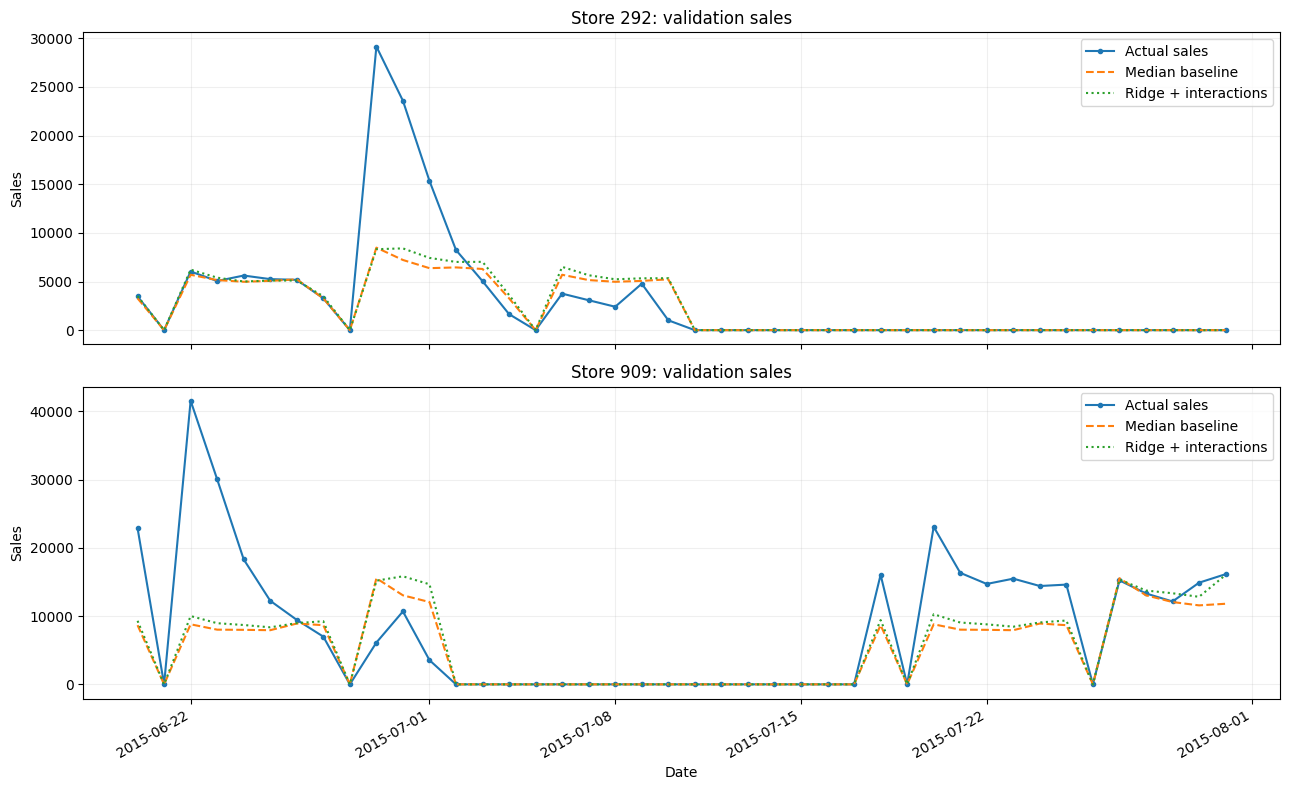

In [18]:
error_details = validation_review.loc[
    validation_review["Sales"].gt(0)
].copy()

error_details["Baseline_APE_pct"] = (
    (
        error_details["Baseline_prediction"]
        - error_details["Sales"]
    ).abs()
    / error_details["Sales"]
    * 100
)

error_details["Ridge_APE_pct"] = (
    (
        error_details["Ridge_interactions"]
        - error_details["Sales"]
    ).abs()
    / error_details["Sales"]
    * 100
)

print("10 largest baseline percentage errors:")
display(
    error_details.sort_values(
        "Baseline_APE_pct", ascending=False
    )[
        [
            "Store", "Date", "Promo", "Sales",
            "Baseline_prediction", "Ridge_interactions",
            "Baseline_APE_pct", "Ridge_APE_pct",
        ]
    ].head(10).round({
        "Baseline_prediction": 2,
        "Ridge_interactions": 2,
        "Baseline_APE_pct": 2,
        "Ridge_APE_pct": 2,
    })
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

for ax, store_id in zip(axes, [292, 909]):
    store_view = (
        validation_review.loc[
            validation_review["Store"].eq(store_id)
        ]
        .sort_values("Date")
        .copy()
    )

    ax.plot(
        store_view["Date"], store_view["Sales"],
        label="Actual sales", marker="o", markersize=3,
    )
    ax.plot(
        store_view["Date"], store_view["Baseline_prediction"],
        label="Median baseline", linestyle="--",
    )
    ax.plot(
        store_view["Date"], store_view["Ridge_interactions"],
        label="Ridge + interactions", linestyle=":",
    )

    ax.set_title(f"Store {store_id}: validation sales")
    ax.set_ylabel("Sales")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [19]:
closure_rows = []

for store_id in [292, 909]:
    history = (
        train_merged.loc[
            train_merged["Store"].eq(store_id),
            ["Store", "Date", "Open", "Sales"],
        ]
        .sort_values("Date")
        .reset_index(drop=True)
    )

    closed = history.loc[history["Open"].eq(0)].copy()

    # A new closure run starts whenever closed dates are not consecutive.
    closed["Run"] = (
        closed["Date"].diff().dt.days.ne(1).cumsum()
    )

    for _, run in closed.groupby("Run"):
        start = run["Date"].min()
        end = run["Date"].max()

        # Show extended closure runs overlapping validation.
        if (
            len(run) < 3
            or end < validation_start
            or start > validation_end
        ):
            continue

        before = history.loc[
            history["Date"].eq(start - pd.Timedelta(days=1))
        ]
        after = history.loc[
            history["Date"].eq(end + pd.Timedelta(days=1))
        ]

        closure_rows.append({
            "Store": store_id,
            "Closed_from": start.date(),
            "Closed_through": end.date(),
            "Recorded_closed_days": len(run),
            "Sales_day_before": (
                before["Sales"].iloc[0] if len(before) else np.nan
            ),
            "Sales_day_after": (
                after["Sales"].iloc[0] if len(after) else np.nan
            ),
            "Continues_to_data_end": end.eq(history["Date"].max())
            if isinstance(end, pd.Series)
            else end == history["Date"].max(),
        })

closure_summary = pd.DataFrame(closure_rows)
display(closure_summary)

print(
    "Closure dates describe recorded Open=0 days; "
    "they do not identify the reason for closure."
)

,Store,Closed_from,Closed_through,Recorded_closed_days,Sales_day_before,Sales_day_after,Continues_to_data_end
0,292,2015-07-11,2015-07-31,21,1012,NaN,True
1,909,2015-07-02,2015-07-17,16,3547,16051.0,False


Closure dates describe recorded Open=0 days; they do not identify the reason for closure.


In [20]:
modelling_tables_dir = project_dir / "reports" / "tables"
modelling_tables_dir.mkdir(parents=True, exist_ok=True)

modelling_tables = {
    "model_comparison": model_comparison.rename_axis("Model").reset_index(),
    "validation_promotion_errors": promo_error_summary,
    "validation_weekly_errors": weekly_error_summary,
    "validation_store_errors": store_error_summary,
    "validation_closure_review": closure_summary,
    "validation_predictions_baseline_ridge": validation_review,
    "largest_baseline_percentage_errors": (
        error_details.sort_values(
            "Baseline_APE_pct", ascending=False
        ).head(50)
    ),
}

for name, table in modelling_tables.items():
    table.to_csv(
        modelling_tables_dir / f"{name}.csv",
        index=False,
    )

print(f"Saved {len(modelling_tables)} modelling tables.")
print("Location:", modelling_tables_dir)

Saved 7 modelling tables.
Location: d:\DigiCrome Academy\Internship\Nexthikes\P6\reports\tables


## Initial modelling findings

- Validation covers 20 June–31 July 2015, a 42-day horizon.
- The store–weekday–promotion median baseline has the lowest
  overall RMSPE so far: 14.49%.
- Log-sales Ridge with store interactions achieves the lowest
  overall RMSE so far: 1,037.93, but its RMSPE is 16.30%.
- The baseline has lower RMSPE in every validation week and
  in both promotion groups.
- Store-specific interactions substantially improve Ridge.
- Large errors include low-sales days immediately before
  extended recorded closures at Stores 292 and 909.
- Known closed days receive zero predictions. This does not
  capture unusual sales on neighbouring open days.
- Closure reasons are unknown; no records were removed.
- Validation results are development backtests because this
  period has been inspected and used for model comparisons.

In [21]:
%pip install catboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import catboost
from catboost import CatBoostRegressor

print("CatBoost version:", catboost.__version__)
print("CatBoost imported successfully.")

CatBoost version: 1.2.10
CatBoost imported successfully.


In [23]:
def prepare_catboost_inputs(inputs):
    result = inputs.copy()

    for column in categorical_features:
        result[column] = (
            result[column]
            .fillna("Unknown")
            .astype(str)
        )

    for column in numeric_features:
        result[column] = result[column].astype(float)

    return result


X_train_cat = prepare_catboost_inputs(X_train)
X_valid_cat = prepare_catboost_inputs(X_valid)

assert X_train_cat.index.equals(y_train.index)
assert X_valid_cat.index.equals(y_valid.index)
assert X_train_cat.columns.equals(X_valid_cat.columns)

catboost_model = CatBoostRegressor(
    iterations=600,
    depth=8,
    learning_rate=0.05,
    loss_function="RMSE",
    cat_features=categorical_features,
    random_seed=42,
    thread_count=4,
    allow_writing_files=False,
    verbose=100,
)

start_time = perf_counter()
print("Training CatBoost on log sales...", flush=True)

catboost_model.fit(
    X_train_cat,
    np.log1p(y_train),
)

# Return predictions to original sales units.
catboost_valid_predictions = np.clip(
    np.expm1(catboost_model.predict(X_valid_cat)),
    0,
    None,
)

# Preserve the same known-closure rule used by other models.
catboost_valid_predictions[
    valid_features["Open"].eq(0).to_numpy()
] = 0.0

assert np.isfinite(catboost_valid_predictions).all()

catboost_metrics = evaluate_sales(
    y_valid,
    catboost_valid_predictions,
)

model_comparison.loc[
    "CatBoost — log sales",
    list(catboost_metrics),
] = list(catboost_metrics.values())

display(
    model_comparison.sort_values("RMSPE_pct").round(2)
)

print(
    f"Training and prediction time: "
    f"{(perf_counter() - start_time) / 60:.2f} minutes"
)
print("CatBoost evaluation completed.")

Training CatBoost on log sales...
0:	learn: 0.4168673	total: 1.12s	remaining: 11m 11s
100:	learn: 0.1884180	total: 1m 58s	remaining: 9m 43s
200:	learn: 0.1742708	total: 4m 7s	remaining: 8m 11s
300:	learn: 0.1662746	total: 6m 34s	remaining: 6m 31s
400:	learn: 0.1604261	total: 9m 8s	remaining: 4m 32s
500:	learn: 0.1563919	total: 11m 28s	remaining: 2m 15s
599:	learn: 0.1531004	total: 13m 35s	remaining: 0us


,MAE,RMSE,RMSPE_pct
Store–weekday–promotion median,658.57,1065.70,14.49
CatBoost — log sales,643.00,1017.66,15.35
Ridge — log sales + interactions,673.68,1037.93,16.30
Random Forest,802.73,1243.48,21.05
Ridge — log sales,804.04,1227.93,22.22
Ridge regression,854.99,1263.14,25.07


Training and prediction time: 13.73 minutes
CatBoost evaluation completed.


In [24]:
import json

models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model.
catboost_path = models_dir / "catboost_log_sales_v1.cbm"
catboost_model.save_model(str(catboost_path))

# Save the input schema and prediction rules.
metadata = {
    "model": "CatBoostRegressor",
    "catboost_version": catboost.__version__,
    "feature_columns": list(X_train_cat.columns),
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "target_transform": "log1p",
    "prediction_transform": "expm1, then clip to minimum 0",
    "closed_day_rule": "Set prediction to 0 when Open == 0",
    "categorical_missing_value": "Unknown",
    "training_end": str(train_part["Date"].max().date()),
    "validation_start": str(validation_start.date()),
    "validation_end": str(validation_end.date()),
    "validation_metrics": {
        name: float(value)
        for name, value in catboost_metrics.items()
    },
}

metadata_path = models_dir / "catboost_log_sales_v1_metadata.json"
metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

# Save predictions with explicit Store–Date identifiers.
catboost_validation_results = valid_features[
    ["Store", "Date", "Open", "Promo", "Sales"]
].copy()

catboost_validation_results["CatBoost_prediction"] = (
    catboost_valid_predictions
)

modelling_tables_dir.mkdir(parents=True, exist_ok=True)

catboost_validation_results.to_csv(
    modelling_tables_dir / "catboost_validation_predictions.csv",
    index=False,
)

model_comparison.rename_axis("Model").reset_index().to_csv(
    modelling_tables_dir / "model_comparison.csv",
    index=False,
)

# Verify that the saved model reloads and reproduces predictions.
reloaded_catboost = CatBoostRegressor()
reloaded_catboost.load_model(str(catboost_path))

sample_inputs = X_valid_cat.iloc[:100]

np.testing.assert_allclose(
    reloaded_catboost.predict(sample_inputs),
    catboost_model.predict(sample_inputs),
    rtol=1e-10,
    atol=1e-10,
)

print("CatBoost model and metadata saved.")
print("Validation predictions and model comparison saved.")
print("Reload check passed: predictions match.")
print("Model location:", catboost_path)

CatBoost model and metadata saved.
Validation predictions and model comparison saved.
Reload check passed: predictions match.
Model location: d:\DigiCrome Academy\Internship\Nexthikes\P6\models\catboost_log_sales_v1.cbm


In [25]:
# Match predictions explicitly by Store and Date.
blend_review = catboost_validation_results.merge(
    baseline_valid[
        ["Store", "Date", "Baseline_prediction"]
    ],
    on=["Store", "Date"],
    how="left",
    validate="one_to_one",
)

assert len(blend_review) == len(valid_features)
assert blend_review[
    ["Baseline_prediction", "CatBoost_prediction"]
].notna().all().all()

blend_review["Blend_prediction"] = (
    0.5 * blend_review["Baseline_prediction"]
    + 0.5 * blend_review["CatBoost_prediction"]
)

blend_review["Forecast_week"] = (
    (blend_review["Date"] - validation_start).dt.days // 7 + 1
)

blend_metrics = evaluate_sales(
    blend_review["Sales"],
    blend_review["Blend_prediction"],
)

model_comparison.loc[
    "50–50 baseline + CatBoost",
    list(blend_metrics),
] = list(blend_metrics.values())

print("Overall validation comparison:")
display(
    model_comparison.sort_values("RMSPE_pct").round(2)
)

weekly_rows = []

for week, group in blend_review.groupby("Forecast_week"):
    for model_name, prediction_column in {
        "Baseline": "Baseline_prediction",
        "CatBoost": "CatBoost_prediction",
        "50–50 blend": "Blend_prediction",
    }.items():
        weekly_rows.append({
            "Forecast_week": week,
            "Model": model_name,
            **evaluate_sales(
                group["Sales"],
                group[prediction_column],
            ),
        })

blend_weekly_summary = pd.DataFrame(weekly_rows)

print("\nWeekly RMSPE (%):")
display(
    blend_weekly_summary.pivot(
        index="Forecast_week",
        columns="Model",
        values="RMSPE_pct",
    ).round(2)
)

Overall validation comparison:


,MAE,RMSE,RMSPE_pct
50–50 baseline + CatBoost,587.61,945.42,13.61
Store–weekday–promotion median,658.57,1065.70,14.49
CatBoost — log sales,643.00,1017.66,15.35
Ridge — log sales + interactions,673.68,1037.93,16.30
Random Forest,802.73,1243.48,21.05
Ridge — log sales,804.04,1227.93,22.22
Ridge regression,854.99,1263.14,25.07



Weekly RMSPE (%):


Model,50–50 blend,Baseline,CatBoost
Forecast_week,,,
1,12.14,11.95,14.01
2,14.12,16.04,16.31
3,15.68,15.50,18.17
4,12.17,12.60,13.35
5,12.83,13.65,13.61
6,14.33,16.59,16.04


In [26]:
# Preserve the blend results.
model_comparison.rename_axis("Model").reset_index().to_csv(
    modelling_tables_dir / "model_comparison.csv",
    index=False,
)

blend_review.to_csv(
    modelling_tables_dir / "blend_validation_predictions.csv",
    index=False,
)

blend_weekly_summary.to_csv(
    modelling_tables_dir / "blend_weekly_errors.csv",
    index=False,
)

# Create a separate, earlier 42-day validation window.
backtest_end = validation_start - pd.Timedelta(days=1)
backtest_start = backtest_end - pd.Timedelta(days=41)

backtest_train = train_merged.loc[
    train_merged["Date"] < backtest_start
].copy()

backtest_valid = train_merged.loc[
    train_merged["Date"].between(backtest_start, backtest_end)
].copy()

assert backtest_train["Date"].max() < backtest_valid["Date"].min()
assert backtest_valid["Date"].nunique() == 42
assert backtest_valid["Date"].max() < validation_start

# Reuse our deterministic feature functions.
def build_sales_features(data):
    return add_promo2_features(
        add_competition_features(
            add_calendar_features(data)
        )
    )

backtest_train_features = build_sales_features(backtest_train)
backtest_valid_features = build_sales_features(backtest_valid)

backtest_open = backtest_train_features.loc[
    backtest_train_features["Open"].eq(1)
].copy()

X_backtest_train_cat = prepare_catboost_inputs(
    select_model_inputs(backtest_open)
)
y_backtest_train = backtest_open["Sales"].astype(float)

X_backtest_valid_cat = prepare_catboost_inputs(
    select_model_inputs(backtest_valid_features)
)
y_backtest_valid = backtest_valid_features["Sales"].astype(float)

assert X_backtest_train_cat.index.equals(y_backtest_train.index)
assert X_backtest_valid_cat.index.equals(y_backtest_valid.index)

for name, frame in [
    ("Earlier training", backtest_train),
    ("Earlier validation", backtest_valid),
]:
    print(
        f"{name}: {len(frame):,} rows | "
        f"{frame['Date'].min().date()} to "
        f"{frame['Date'].max().date()}"
    )

print("\nEarlier CatBoost training inputs:", X_backtest_train_cat.shape)
print("Earlier validation inputs:", X_backtest_valid_cat.shape)
print("Second backtest prepared successfully.")

Earlier training: 923,549 rows | 2013-01-01 to 2015-05-08
Earlier validation: 46,830 rows | 2015-05-09 to 2015-06-19

Earlier CatBoost training inputs: (766637, 27)
Earlier validation inputs: (46830, 27)
Second backtest prepared successfully.


In [27]:
# Rebuild the baseline using ONLY the earlier training period.
backtest_baseline_train = backtest_train.loc[
    backtest_train["Open"].eq(1)
]

backtest_lookup = (
    backtest_baseline_train
    .groupby(["Store", "DayOfWeek", "Promo"])["Sales"]
    .median()
    .rename("Baseline_prediction")
    .reset_index()
)

backtest_store_medians = (
    backtest_baseline_train.groupby("Store")["Sales"].median()
)
backtest_global_median = backtest_baseline_train["Sales"].median()

# Attach CatBoost predictions before merging to preserve alignment.
backtest_results = backtest_valid_features[
    ["Store", "Date", "DayOfWeek", "Promo", "Open", "Sales"]
].copy()

# Create a fresh model with the same configuration.
backtest_catboost_model = CatBoostRegressor(
    **catboost_model.get_params()
)

start_time = perf_counter()
print("Training CatBoost for the earlier backtest...", flush=True)

backtest_catboost_model.fit(
    X_backtest_train_cat,
    np.log1p(y_backtest_train),
)

backtest_results["CatBoost_prediction"] = np.clip(
    np.expm1(
        backtest_catboost_model.predict(X_backtest_valid_cat)
    ),
    0,
    None,
)

backtest_results = backtest_results.merge(
    backtest_lookup,
    on=["Store", "DayOfWeek", "Promo"],
    how="left",
    validate="many_to_one",
)

backtest_results["Baseline_prediction"] = (
    backtest_results["Baseline_prediction"]
    .fillna(backtest_results["Store"].map(backtest_store_medians))
    .fillna(backtest_global_median)
)

prediction_cols = ["Baseline_prediction", "CatBoost_prediction"]

backtest_results.loc[
    backtest_results["Open"].eq(0), prediction_cols
] = 0.0

backtest_results["Blend_prediction"] = (
    0.5 * backtest_results["Baseline_prediction"]
    + 0.5 * backtest_results["CatBoost_prediction"]
)

assert len(backtest_results) == len(backtest_valid)
assert np.isfinite(
    backtest_results[
        prediction_cols + ["Blend_prediction"]
    ].to_numpy()
).all()

backtest_metrics = pd.DataFrame.from_dict(
    {
        name: evaluate_sales(
            backtest_results["Sales"],
            backtest_results[column],
        )
        for name, column in {
            "Median baseline": "Baseline_prediction",
            "CatBoost — log sales": "CatBoost_prediction",
            "50–50 baseline + CatBoost": "Blend_prediction",
        }.items()
    },
    orient="index",
)

print("\nEarlier backtest: 9 May–19 June 2015")
display(backtest_metrics.sort_values("RMSPE_pct").round(2))

# Save this separate backtest immediately.
backtest_catboost_model.save_model(
    str(models_dir / "catboost_earlier_backtest.cbm")
)

backtest_results.to_csv(
    modelling_tables_dir / "earlier_backtest_predictions.csv",
    index=False,
)

backtest_metrics.rename_axis("Model").reset_index().to_csv(
    modelling_tables_dir / "earlier_backtest_metrics.csv",
    index=False,
)

print(
    f"Elapsed time: "
    f"{(perf_counter() - start_time) / 60:.2f} minutes"
)
print("Earlier backtest completed and saved.")

Training CatBoost for the earlier backtest...
0:	learn: 0.4179091	total: 1.33s	remaining: 13m 15s
100:	learn: 0.1887647	total: 1m 47s	remaining: 8m 53s
200:	learn: 0.1746715	total: 3m 52s	remaining: 7m 40s
300:	learn: 0.1662728	total: 5m 49s	remaining: 5m 47s
400:	learn: 0.1615055	total: 7m 43s	remaining: 3m 50s
500:	learn: 0.1577946	total: 9m 45s	remaining: 1m 55s
599:	learn: 0.1546456	total: 11m 54s	remaining: 0us

Earlier backtest: 9 May–19 June 2015


,MAE,RMSE,RMSPE_pct
50–50 baseline + CatBoost,621.39,992.40,14.18
CatBoost — log sales,654.98,1061.86,14.76
Median baseline,673.84,1053.16,15.84


Elapsed time: 12.04 minutes
Earlier backtest completed and saved.


In [28]:
# Prepare all labelled data for the final model.
full_train_features = build_sales_features(train_merged)

full_train_open = full_train_features.loc[
    full_train_features["Open"].eq(1)
].copy()

X_full_cat = prepare_catboost_inputs(
    select_model_inputs(full_train_open)
)
y_full = full_train_open["Sales"].astype(float)

# Prepare test data independently.
final_test_features = build_sales_features(test_merged)

missing_open = final_test_features["Open"].isna()

print("Test rows with missing Open:", int(missing_open.sum()))
print(
    "Affected stores:",
    final_test_features.loc[missing_open, "Store"].unique().tolist(),
)

# Preserve the previously documented assumption for Store 622.
assert final_test_features.loc[
    missing_open, "Store"
].isin([622]).all(), "Unexpected store with missing Open; review first."

final_test_features["OpenWasMissing"] = missing_open.astype(int)
final_test_features.loc[missing_open, "Open"] = 1

X_final_test_cat = prepare_catboost_inputs(
    select_model_inputs(final_test_features)
)

assert X_full_cat.index.equals(y_full.index)
assert X_full_cat.columns.equals(X_final_test_cat.columns)
assert final_test_features["Id"].is_unique
assert final_test_features["Open"].isin([0, 1]).all()
assert train_merged["Date"].max() < final_test_features["Date"].min()

print("\nFull training inputs:", X_full_cat.shape)
print("Final test inputs:", X_final_test_cat.shape)
print("Training ends:", full_train_open["Date"].max().date())
print(
    "Test dates:",
    final_test_features["Date"].min().date(),
    "to",
    final_test_features["Date"].max().date(),
)
print("\nFinal training and test inputs prepared.")

Test rows with missing Open: 11
Affected stores: [622]

Full training inputs: (844392, 27)
Final test inputs: (41088, 27)
Training ends: 2015-07-31
Test dates: 2015-08-01 to 2015-09-17

Final training and test inputs prepared.


In [ ]:
start_time = perf_counter()

models_dir.mkdir(parents=True, exist_ok=True)
predictions_dir = project_dir / "predictions"
predictions_dir.mkdir(parents=True, exist_ok=True)

# Train a fresh model using all available labelled open days.
final_catboost_model = CatBoostRegressor(
    **catboost_model.get_params()
)

print("Training final CatBoost model...", flush=True)

final_catboost_model.fit(
    X_full_cat,
    np.log1p(y_full),
)

# Save immediately after training.
final_model_path = models_dir / "catboost_final.cbm"
final_catboost_model.save_model(str(final_model_path))

# Attach predictions before merging to preserve row alignment.
assert X_final_test_cat.index.equals(final_test_features.index)

final_predictions = final_test_features[
    ["Id", "Store", "Date", "DayOfWeek", "Promo",
     "Open", "OpenWasMissing"]
].copy()

final_predictions["CatBoost_prediction"] = np.clip(
    np.expm1(final_catboost_model.predict(X_final_test_cat)),
    0,
    None,
)

# Rebuild the baseline using all labelled open days.
final_baseline_keys = ["Store", "DayOfWeek", "Promo"]

final_baseline_lookup = (
    full_train_open.groupby(final_baseline_keys)["Sales"]
    .median()
    .rename("Baseline_prediction")
    .reset_index()
)

final_store_medians = (
    full_train_open.groupby("Store")["Sales"].median()
)
final_global_median = float(full_train_open["Sales"].median())

final_predictions = final_predictions.merge(
    final_baseline_lookup,
    on=final_baseline_keys,
    how="left",
    validate="many_to_one",
)

final_predictions["Baseline_prediction"] = (
    final_predictions["Baseline_prediction"]
    .fillna(final_predictions["Store"].map(final_store_medians))
    .fillna(final_global_median)
)

# Apply the known-closure rule to both components.
component_columns = ["Baseline_prediction", "CatBoost_prediction"]

final_predictions.loc[
    final_predictions["Open"].eq(0), component_columns
] = 0.0

final_predictions["Sales"] = (
    0.5 * final_predictions["Baseline_prediction"]
    + 0.5 * final_predictions["CatBoost_prediction"]
)

# Match the original test-file order by Id.
submission = test[["Id"]].merge(
    final_predictions[["Id", "Sales"]],
    on="Id",
    how="left",
    validate="one_to_one",
    sort=False,
)

assert len(submission) == len(test)
assert submission["Id"].tolist() == test["Id"].tolist()
assert np.isfinite(submission["Sales"]).all()
assert submission["Sales"].ge(0).all()
assert final_predictions.loc[
    final_predictions["Open"].eq(0), "Sales"
].eq(0).all()

# Preserve the baseline components needed to reuse the blend.
joblib.dump(
    {
        "keys": final_baseline_keys,
        "lookup": final_baseline_lookup,
        "store_medians": final_store_medians,
        "global_median": final_global_median,
        "baseline_weight": 0.5,
        "catboost_weight": 0.5,
    },
    models_dir / "final_baseline_bundle.joblib",
)

submission_path = predictions_dir / "submission.csv"

submission.to_csv(submission_path, index=False)
final_predictions.to_csv(
    predictions_dir / "test_predictions_detailed.csv",
    index=False,
)

print("\nFinal model and baseline saved.")
print("Forecast rows:", len(submission))
print("Submission location:", submission_path)
print(
    f"Elapsed time: "
    f"{(perf_counter() - start_time) / 60:.2f} minutes"
)

display(submission.head(10).round({"Sales": 2}))
logger.info("Submission saved: rows=%s, path=%s", len(submission), submission_path)


In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor

# Reload the saved artifacts.
loaded_final_model = CatBoostRegressor()
loaded_final_model.load_model(
    str(models_dir / "catboost_final.cbm")
)
loaded_baseline = joblib.load(
    models_dir / "final_baseline_bundle.joblib"
)
saved_submission = pd.read_csv(
    predictions_dir / "submission.csv"
)

# Reproduce a small sample using both saved model components.
sample_features = final_test_features.iloc[:200].copy()
sample_inputs = X_final_test_cat.iloc[:200].copy()
assert sample_inputs.index.equals(sample_features.index)

sample_predictions = sample_features[
    ["Id", "Store", "DayOfWeek", "Promo", "Open"]
].copy()

sample_predictions["CatBoost_prediction"] = np.clip(
    np.expm1(loaded_final_model.predict(sample_inputs)), 0, None
)

sample_predictions = sample_predictions.merge(
    loaded_baseline["lookup"],
    on=loaded_baseline["keys"],
    how="left",
    validate="many_to_one",
)

sample_predictions["Baseline_prediction"] = (
    sample_predictions["Baseline_prediction"]
    .fillna(sample_predictions["Store"].map(
        loaded_baseline["store_medians"]
    ))
    .fillna(loaded_baseline["global_median"])
)

sample_predictions["Reloaded_sales"] = (
    loaded_baseline["baseline_weight"]
    * sample_predictions["Baseline_prediction"]
    + loaded_baseline["catboost_weight"]
    * sample_predictions["CatBoost_prediction"]
)
sample_predictions.loc[
    sample_predictions["Open"].eq(0), "Reloaded_sales"
] = 0.0

reload_check = sample_predictions.merge(
    saved_submission,
    on="Id",
    how="left",
    validate="one_to_one",
)

np.testing.assert_allclose(
    reload_check["Reloaded_sales"],
    reload_check["Sales"],
    rtol=1e-9,
    atol=1e-6,
)

# Validate the complete saved submission.
assert saved_submission.columns.tolist() == ["Id", "Sales"]
assert len(saved_submission) == len(test)
assert saved_submission["Id"].is_unique
assert saved_submission["Id"].tolist() == test["Id"].tolist()
assert np.isfinite(saved_submission["Sales"]).all()
assert saved_submission["Sales"].ge(0).all()

closed_ids = final_test_features.loc[
    final_test_features["Open"].eq(0), "Id"
]
assert saved_submission.loc[
    saved_submission["Id"].isin(closed_ids), "Sales"
].eq(0).all()

# Document the final model and assumptions.
final_metadata = {
    "model": "50–50 median baseline + CatBoost on log1p sales",
    "catboost_file": "catboost_final.cbm",
    "baseline_file": "final_baseline_bundle.joblib",
    "feature_columns": list(X_full_cat.columns),
    "categorical_features": list(categorical_features),
    "numeric_features": list(numeric_features),
    "training_rows": len(X_full_cat),
    "training_end": str(full_train_open["Date"].max().date()),
    "test_start": str(final_test_features["Date"].min().date()),
    "test_end": str(final_test_features["Date"].max().date()),
    "forecast_rows": len(saved_submission),
    "closed_store_prediction": 0,
    "missing_open_assumption": "Assume Open=1",
    "test_rows_with_missing_open": int(
        final_test_features["OpenWasMissing"].sum()
    ),
    "validation_rmspe_pct_rounded": {
        "2015-05-09_to_2015-06-19": 14.18,
        "2015-06-20_to_2015-07-31": 13.61,
    },
    "validation_note": (
        "Two development backtests, each 42 days. "
        "The test horizon is 48 days; its final six-day "
        "forecast horizon was not covered by these backtests."
    ),
}

metadata_path = models_dir / "final_model_metadata.json"
metadata_path.write_text(
    json.dumps(final_metadata, indent=2),
    encoding="utf-8",
)

print("Saved model and baseline reload check passed.")
print(f"Submission checks passed: {len(saved_submission):,} rows.")
print("Final model metadata saved.")
print("No retraining performed.")

SyntaxError: invalid syntax. Perhaps you forgot a comma? (48880702.py, line 9)

## Final model selection and results

The selected forecasting method averages two predictions equally:
- Historical median sales grouped by store, weekday, and promotion status.
- CatBoost trained on log1p-transformed sales.

### Time-based validation

| Validation period | Median baseline RMSPE | CatBoost RMSPE | 50–50 blend RMSPE |
|---|---:|---:|---:|
| 9 May–19 June 2015 | 15.84% | 14.76% | **14.18%** |
| 20 June–31 July 2015 | 14.49% | 15.35% | **13.61%** |

The blend achieved the lowest MAE, RMSE, and RMSPE among these
three methods in both validation periods. This supports selecting
the blend over either individual component.

### Final training and forecasts

The final CatBoost model was trained on 844,392 open-store
observations using 27 input features, with training data ending
on 31 July 2015. The historical median baseline was also rebuilt
using the full open-store training data.

A total of 41,088 forecasts were generated for 1 August–17 September
2015. Known closed stores received zero predictions. The 11 test
records with missing Open values, all belonging to store 622,
were assumed open and flagged for traceability.

### Saved outputs

- `models/catboost_final.cbm`
- `models/final_baseline_bundle.joblib`
- `models/final_model_metadata.json`
- `predictions/submission.csv`
- `predictions/test_predictions_detailed.csv`

The saved model and baseline were reloaded successfully, and
sample predictions matched the exported forecasts. Submission
checks confirmed the expected row count, unique IDs, original
ID order, finite non-negative predictions, and zero forecasts
for known closed stores.

### Limitations

Both validation periods were used during model development;
neither represents an untouched final evaluation set.

Each backtest covered 42 days, while the test forecast spans
48 days. Forecast performance beyond day 42 was not evaluated.

Unusual sales around prolonged closures were difficult to predict.
The closure records do not establish the reasons for those changes.

Test sales are unavailable, so test forecast accuracy cannot
be measured from the supplied data.

,Feature,Importance
0,Store,37.001
7,Promo,20.395
1,DayOfWeek,9.256
9,CompetitionDistance,5.229
22,WeekOfYear,4.650
21,Day,4.094
26,DaysSince2013,3.178
2,StoreType,3.144
20,Month,2.625
12,CompetitionOpenMonths,1.948


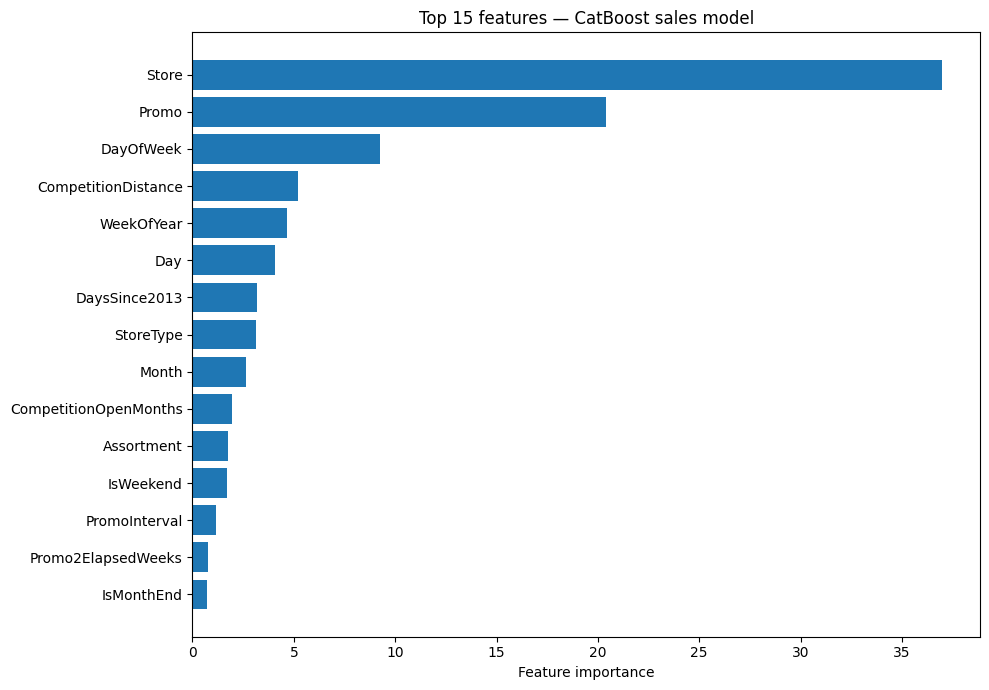

2026-10-14 16:27:29,632 | INFO | rossmann.modelling | CatBoost feature importance calculated and saved.


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

importance_values = loaded_final_model.get_feature_importance(
    type="PredictionValuesChange",
    thread_count=4,
)

feature_importance = pd.DataFrame({
    "Feature": loaded_final_model.feature_names_,
    "Importance": importance_values,
}).sort_values("Importance", ascending=False)

assert np.isfinite(feature_importance["Importance"]).all()

display(feature_importance.head(15).round({"Importance": 3}))

top_features = feature_importance.head(15).sort_values("Importance")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_features["Feature"], top_features["Importance"])
ax.set_title("Top 15 features — CatBoost sales model")
ax.set_xlabel("Feature importance")
fig.tight_layout()

figures_dir = project_dir / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
modelling_tables_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "catboost_feature_importance.png",
    dpi=200,
    bbox_inches="tight",
)
feature_importance.to_csv(
    modelling_tables_dir / "catboost_feature_importance.csv",
    index=False,
)

plt.show()
logger.info("CatBoost feature importance calculated and saved.")

### Feature importance interpretation

Store identity (37.00), promotion status (20.40), and day of
the week (9.26) have the highest CatBoost feature-importance
scores. Together, they account for 66.65% of total importance,
indicating that the model relies strongly on store-specific
differences, promotions, and weekly patterns.

Competition distance and week of the year also contribute,
alongside other calendar and store characteristics.

These scores describe the CatBoost component, not the complete
50–50 blend. They do not show whether a feature increases or
decreases sales, and they do not establish causal effects.
Related features may share importance.

### Training loss and evaluation metrics

CatBoost was trained using RMSE on log1p-transformed sales.
The transformation reduces the influence of very large sales
values and supports learning differences on a relative scale.
This training objective is not identical to RMSPE.

RMSPE was the primary model-selection metric because it measures
errors relative to actual sales, allowing comparison across
stores of different sizes. It was calculated only for positive
actual sales to avoid division by zero.

MAE and RMSE were also reported in original sales units.
MAE measures average absolute error, while RMSE gives greater
weight to large errors.

The equal-weight baseline–CatBoost blend achieved the lowest
MAE, RMSE, and RMSPE among these three methods in both
development backtests.

In [36]:
# Calibrate on the earlier backtest's open-store observations.
calibration = backtest_results.loc[
    backtest_results["Open"].eq(1)
].copy()

# Log-scale errors allow wider intervals for larger forecasts.
calibration_errors = np.abs(
    np.log1p(calibration["Sales"].to_numpy())
    - np.log1p(calibration["Blend_prediction"].to_numpy())
)

assert len(calibration_errors) > 0
assert np.isfinite(calibration_errors).all()

interval_radius = float(
    np.quantile(calibration_errors, 0.90, method="higher")
)

def add_sales_intervals(data, prediction_column, radius):
    result = data.copy()
    predictions = result[prediction_column].to_numpy(dtype=float)

    assert np.isfinite(predictions).all()
    assert (predictions >= 0).all()

    log_predictions = np.log1p(predictions)

    result["Sales_lower_90"] = np.maximum(
        np.expm1(log_predictions - radius), 0
    )
    result["Sales_upper_90"] = np.maximum(
        np.expm1(log_predictions + radius), 0
    )

    # Conditional on the supplied store-opening schedule.
    result.loc[
        result["Open"].eq(0),
        ["Sales_lower_90", "Sales_upper_90"],
    ] = 0.0

    return result

# Evaluate on the later backtest.
interval_validation = add_sales_intervals(
    blend_review, "Blend_prediction", interval_radius
)

interval_validation["Covered"] = (
    interval_validation["Sales"].between(
        interval_validation["Sales_lower_90"],
        interval_validation["Sales_upper_90"],
    )
)
interval_validation["Interval_width"] = (
    interval_validation["Sales_upper_90"]
    - interval_validation["Sales_lower_90"]
)

coverage_rows = []
for label, subset in [
    ("Open days", interval_validation[
        interval_validation["Open"].eq(1)
    ]),
    ("All recorded days", interval_validation),
]:
    coverage_rows.append({
        "Evaluation_group": label,
        "Rows": len(subset),
        "Coverage_pct": 100 * subset["Covered"].mean(),
        "Mean_interval_width": subset["Interval_width"].mean(),
    })

interval_summary = pd.DataFrame(coverage_rows)
display(interval_summary.round(2))

# Apply the same radius to final test forecasts.
test_intervals = add_sales_intervals(
    final_predictions, "Sales", interval_radius
)

interval_validation.to_csv(
    modelling_tables_dir / "prediction_interval_validation.csv",
    index=False,
)
interval_summary.to_csv(
    modelling_tables_dir / "prediction_interval_coverage.csv",
    index=False,
)
test_intervals.to_csv(
    predictions_dir / "test_predictions_with_intervals.csv",
    index=False,
)

joblib.dump(
    {
        "method": "Absolute log1p residual quantile",
        "nominal_coverage": 0.90,
        "radius": interval_radius,
        "calibration_period": "2015-05-09 to 2015-06-19",
        "calibration_population": "Open-store observations",
        "note": (
            "Approximate empirical intervals; temporal dependence, "
            "model refitting and distribution changes can affect coverage."
        ),
    },
    models_dir / "sales_interval_calibration.joblib",
)

logger.info(
    "Prediction intervals saved; log-scale radius=%.4f",
    interval_radius,
)
print("Original submission.csv remains unchanged.")

,Evaluation_group,Rows,Coverage_pct,Mean_interval_width
0,Open days,40282,93.62,3311.23
1,All recorded days,46830,94.52,2848.24


2026-10-14 16:29:32,418 | INFO | rossmann.modelling | Prediction intervals saved; log-scale radius=0.2394


Original submission.csv remains unchanged.


In [37]:
from datetime import datetime, timezone
import shutil
import json

version_time = datetime.now(timezone.utc)
version_id = version_time.strftime("%Y-%m-%d_%H-%M-%S-%f_UTC")

artifact_names = [
    "catboost_final.cbm",
    "final_baseline_bundle.joblib",
    "final_model_metadata.json",
    "sales_interval_calibration.joblib",
]

# Check all source files before creating the version.
for name in artifact_names:
    source = models_dir / name
    if not source.is_file():
        raise FileNotFoundError(f"Required artifact missing: {source}")

version_dir = models_dir / "versions" / version_id
version_dir.mkdir(parents=True, exist_ok=False)

for name in artifact_names:
    shutil.copy2(models_dir / name, version_dir / name)

manifest = {
    "version_id": version_id,
    "archived_at_utc": version_time.isoformat(),
    "description": (
        "Snapshot of the existing final sales blend and interval artifacts. "
        "Timestamp records archiving time, not original training time."
    ),
    "artifacts": artifact_names,
}

(version_dir / "manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

logger.info("Model artifacts archived: %s", version_dir)
print("Timestamped model version saved:")
print(version_dir)
print("No retraining performed.")

2026-10-14 16:30:20,135 | INFO | rossmann.modelling | Model artifacts archived: d:\DigiCrome Academy\Internship\Nexthikes\P6\models\versions\2026-10-14_11-00-20-102420_UTC


Timestamped model version saved:
d:\DigiCrome Academy\Internship\Nexthikes\P6\models\versions\2026-10-14_11-00-20-102420_UTC
No retraining performed.


## Feature scope

The existing model uses its original 27 inputs. Explicit days-before/after-holiday features are not implemented in this model. Adding them requires a versioned feature schema, time-aware validation and retraining; this cleanup does not claim to complete that experiment. Calendar availability must cover the forecast horizon.